<a href="https://colab.research.google.com/github/Ahoyosjara/MPM_200_HoyosJaramillo/blob/main/AlejandroHJ_will__hummers_survive_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [1]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘audio’




In [2]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. HoyosJara!", by = "trilobite")


 ___________________________________________ 
< Welcome to Hummingbird HQ, Dr. HoyosJara! >
 ------------------------------------------- 
       \
        \

          _____
       .'` ,-. `'.
      /   ([ ])   \
     /.-""`(`)`""-.\
      <'```(.)```'>
      <'```(.)```'>
       <'``(.)``'>
   sk   <``\_/``>
         `'---'`

In [3]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

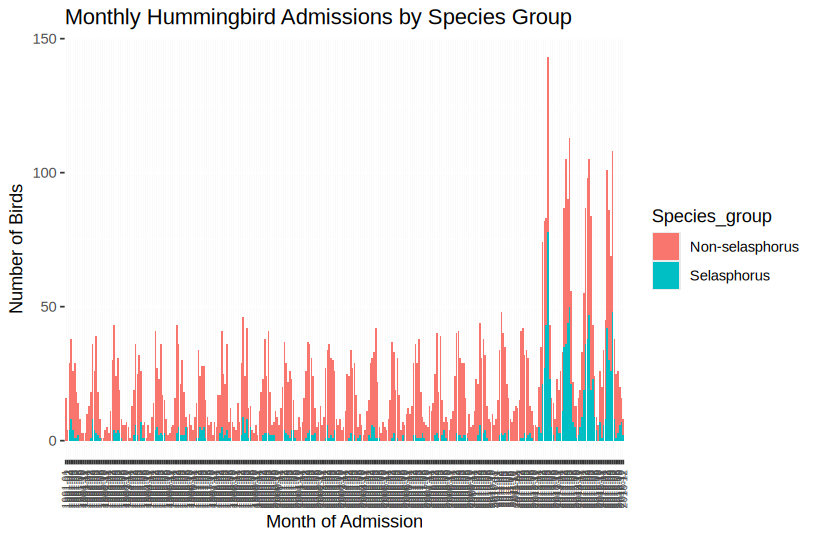

In [4]:
url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200_2026/main/data/Hummingbird_data.csv"
data <- read.csv(url)

# Ensure we have our model_data formatted correctly
model_data <- data
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

# Prepare monthly admissions data by Species group
monthly_species_admissions <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

# Plot the timeline
ggplot(monthly_species_admissions, aes(x = Admitted_month, y = count, fill = Species_group)) +
  geom_col(position = "stack") +
  xlab("Month of Admission") +
  ylab("Number of Birds") +
  labs(title = "Monthly Hummingbird Admissions by Species Group") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, size = 6))

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `6908 birds`.
Now find how many rows and columns `data` has. Has 6908 rows, 12 columns.

In [5]:
dim(data)      # rows, columns
nrow(data)
ncol(data)
head(data)
colnames(data)
data$ID <- as.factor(data$ID)   # text → categories (factor)
levels(data$ID)
length(unique(data$ID))

[1] 6908   12

[1] 6908

[1] 12

,Admitted,Disposition_binary,Place,F_Aid,Species_e,Sex_e,Age_e,Brought_in_after,season,r,Green_Orange,ID
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,1/2/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,1,Winter,found on the ground,Non-selasphorus spp.,1_ANHU
2,1/2/1991,Released,Lindsey,Yes,ANHU,Female-like,adult-like,0,Winter,unknown,Non-selasphorus spp.,2_ANHU
3,1/4/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,suspect torpor-like state,Non-selasphorus spp.,3_ANHU
4,1/5/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,4,Winter,unknown,Non-selasphorus spp.,4_ANHU
5,1/5/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,caught by domestic animal,Non-selasphorus spp.,5_ANHU
6,1/5/1991,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,found on the ground,Non-selasphorus spp.,6_ANHU


[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

[1] "1_ANHU"    "10_ANHU"   "100_ANHU"  "1000_ANHU" "1001_RUHU" "1002_ANHU"
   [7] "1003_ANHU" "1004_ANHU" "1005_ANHU" "1006_ANHU" "1007_ANHU" "1008_ANHU"
  [13] "1009_ANHU" "101_ALHU"  "1010_ANHU" "1011_ALHU" "1012_ANHU" "1013_ANHU"
  [19] "1014_ANHU" "1015_ANHU" "1016_ANHU" "1017_ANHU" "1018_ANHU" "1019_ANHU"
  [25] "102_ALHU"  "1020_ANHU" "1021_ALHU" "1022_ANHU" "1023_ANHU" "1024_ANHU"
  [31] "1025_ANHU" "1026_ANHU" "1027_ANHU" "1028_ANHU" "1029_ANHU" "103_ANHU" 
  [37] "1030_ANHU" "1031_ANHU" "1032_ALHU" "1033_ANHU" "1034_ANHU" "1035_ANHU"
  [43] "1036_ANHU" "1037_ANHU" "1038_ALHU" "1039_ALHU" "104_ANHU"  "1040_ALHU"
  [49] "1041_ANHU" "1042_ANHU" "1043_ANHU" "1044_ANHU" "1045_ANHU" "1046_ALHU"
  [55] "1047_ANHU" "1048_ANHU" "1049_ANHU" "105_ANHU"  "1050_ANHU" "1051_ANHU"
  [61] "1052_ANHU" "1053_ANHU" "1054_ANHU" "1055_ANHU" "1056_ANHU" "1057_ANHU"
  [67] "1058_ANHU" "1059_ANHU" "106_ANHU"  "1060_ANHU" "1061_ANHU" "1062_ANHU"
  [73] "1063_ANHU" "1064_ANHU" "1065_ALHU" "1066_ANHU" "1067_ANHU" "1068_ANHU"
  [79] "1069_ANHU" "107_ALHU"  "1070_ANHU" "1071_ANHU" "1072_ANHU" "1073_ANHU"
  [85] "1074_ANHU" "1075_ANHU" "1076_ANHU" "1077_ANHU" "1078_ANHU" "1079_ANHU"
  [91] "108_ANHU"  "1080_ANHU" "1081_ALHU" "1082_ANHU" "1083_ANHU" "1084_ANHU"
  [97] "1085_BCHU" "1086_BCHU" "1087_ANHU" "1088_ANHU" "1089_ANHU" "109_ANHU" 
 [103] "1090_ANHU" "1091_ANHU" "1092_ANHU" "1093_ANHU" "1094_ANHU" "1095_ANHU"
 [109] "1096_ANHU" "1097_ANHU" "1098_ANHU" "1099_ANHU" "11_ANHU"   "110_ANHU" 
 [115] "1100_ANHU" "1101_ANHU" "1102_ANHU" "1103_ANHU" "1104_ANHU" "1105_ALHU"
 [121] "1106_ANHU" "1107_ALHU" "1108_ANHU" "1109_ALHU" "111_ANHU"  "1110_ANHU"
 [127] "1111_ANHU" "1112_ANHU" "1113_RUHU" "1114_ALHU" "1115_ALHU" "1116_ANHU"
 [133] "1117_ALHU" "1118_ANHU" "1119_ANHU" "112_ANHU"  "1120_ANHU" "1121_ANHU"
 [139] "1122_ANHU" "1123_ANHU" "1124_ANHU" "1125_ANHU" "1126_ANHU" "1127_ANHU"
 [145] "1128_ANHU" "1129_ANHU" "113_ANHU"  "1130_ANHU" "1131_ANHU" "1132_ANHU"
 [151] "1133_ANHU" "1134_ANHU" "1135_ANHU" "1136_ANHU" "1137_ANHU" "1138_ANHU"
 [157] "1139_ANHU" "114_ANHU"  "1140_ANHU" "1141_ANHU" "1142_ANHU" "1143_ANHU"
 [163] "1144_ANHU" "1145_ANHU" "1146_ANHU" "1147_ANHU" "1148_ANHU" "1149_ANHU"
 [169] "115_ANHU"  "1150_ANHU" "1151_ANHU" "1152_ANHU" "1153_ANHU" "1154_ALHU"
 [175] "1155_ANHU" "1156_ANHU" "1157_ANHU" "1158_ANHU" "1159_ANHU" "116_ANHU" 
 [181] "1160_ANHU" "1161_ANHU" "1162_ANHU" "1163_ANHU" "1164_ANHU" "1165_ANHU"
 [187] "1166_ANHU" "1167_ANHU" "1168_ANHU" "1169_ANHU" "117_ANHU"  "1170_ANHU"
 [193] "1171_ANHU" "1172_ANHU" "1173_ANHU" "1174_ANHU" "1175_ANHU" "1176_ANHU"
 [199] "1177_ANHU" "1178_ANHU" "1179_ANHU" "118_ANHU"  "1180_ANHU" "1181_ANHU"
 [205] "1182_ANHU" "1183_ANHU" "1184_ANHU" "1185_ANHU" "1186_ANHU" "1187_ANHU"
 [211] "1188_ANHU" "1189_ANHU" "119_ANHU"  "1190_ANHU" "1191_ANHU" "1192_ANHU"
 [217] "1193_ALHU" "1194_ANHU" "1195_ANHU" "1196_ANHU" "1197_ANHU" "1198_ANHU"
 [223] "1199_ANHU" "12_ANHU"   "120_ANHU"  "1200_ANHU" "1201_ANHU" "1202_ANHU"
 [229] "1203_ANHU" "1204_ANHU" "1205_ALHU" "1206_ALHU" "1207_ANHU" "1208_ANHU"
 [235] "1209_RUHU" "121_ANHU"  "1210_ALHU" "1211_ANHU" "1212_ANHU" "1213_ANHU"
 [241] "1214_ANHU" "1215_ANHU" "1216_ALHU" "1217_ANHU" "1218_ANHU" "1219_ANHU"
 [247] "122_ANHU"  "1220_ANHU" "1221_ANHU" "1222_ANHU" "1223_ANHU" "1224_ANHU"
 [253] "1225_ANHU" "1226_ALHU" "1227_ANHU" "1228_ANHU" "1229_ANHU" "123_ANHU" 
 [259] "1230_ALHU" "1231_ALHU" "1232_ANHU" "1233_ANHU" "1234_ANHU" "1235_ANHU"
 [265] "1236_ANHU" "1237_ANHU" "1238_ANHU" "1239_ANHU" "124_ANHU"  "1240_ALHU"
 [271] "1241_ANHU" "1242_ANHU" "1243_ANHU" "1244_ANHU" "1245_ANHU" "1246_ANHU"
 [277] "1247_ANHU" "1248_ANHU" "1249_ANHU" "125_ANHU"  "1250_ANHU" "1251_ANHU"
 [283] "1252_ANHU" "1253_ANHU" "1254_ANHU" "1255_ALHU" "1256_ANHU" "1257_ALHU"
 [289] "1258_ANHU" "1259_ANHU" "126_ANHU"  "1260_ANHU" "1261_ANHU" "1262_ANHU"
 [295] "1263_ALHU" "1264_ANHU" "1265_ANHU" "1266_ANHU" "1267_ANHU" "1268_ALHU"
 [301] "1269_ANHU" "127_ANHU"  "1270_ANHU" "1271_ALHU

[1] 6908

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [6]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : Factor w/ 6908 levels "1_ANHU","10_ANHU",..: 1 1112 2223 3334 4445 5554 6576 6687 6798 2

✍️ All columns are character except Brought_in_After (integer) and ID (factor). Numer is only Brought_in_After (integer). Admitted is stored as character.  

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [7]:
library(dplyr)
set.seed(0514)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have? 5000 rows and 12 columns

In [8]:
dim(model_data)      # rows, columns
str(model_data)

[1] 5000   12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "3/4/2009" "6/8/2009" "4/4/2014" "12/13/2014" ...
 $ Disposition_binary: chr  "Released" "Died" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "malibu" "malibu" ...
 $ F_Aid             : chr  "No" "No" "Yes" "Yes" ...
 $ Species_e         : chr  "Non-selasphorus" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "unknown" "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "Nestling" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  0 0 0 4 0 0 0 0 0 1 ...
 $ season            : chr  "Spring" "Summer" "Spring" "Winter" ...
 $ r                 : chr  "found on the ground" "window hit" "found on the ground" "window hit" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : Factor w/ 6908 levels "1_ANHU","10_ANHU",..: 2927 3059 5646 5912 5738 3478 374 4993

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis? 10 columns are categorical, one is continous (Brought_in_after). ID is factor variable and is fucntional from the point of view that allows me to obveserve unique IDs.

✍️Name the continuous one(s). Is `ID` a useful variable for analysis? 10 columns are categorical, one is continous (Brought_in_after). ID is factor variable and is fucntional from the point of view that allows me to obveserve unique ID

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [9]:
dir.create("outputs", showWarnings = FALSE)
write.csv(model_data, "outputs/Hummingbird_data_Alejandro.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [10]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4135
Santa Barbara,74
malibu,791


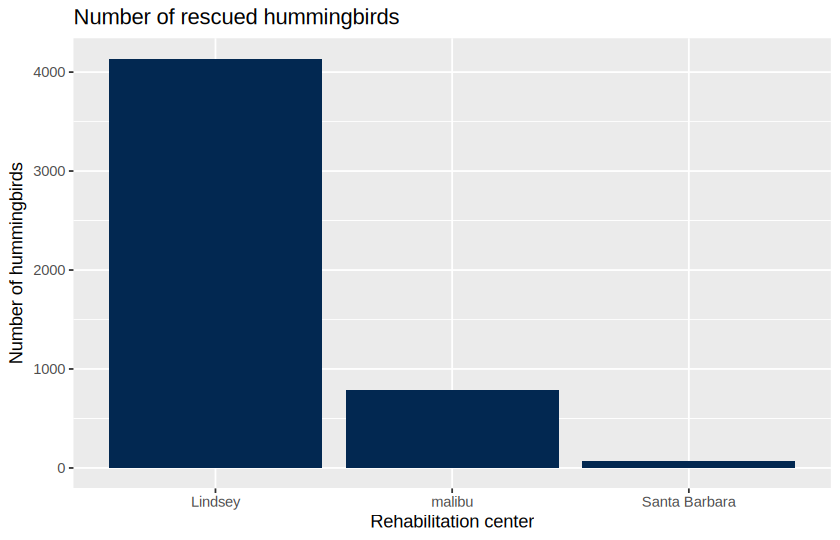

In [11]:
library(ggplot2)
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [12]:
ggsave("outputs/rehab_counts_Alejandro.pdf", p, width = 4, height = 3)
list.files("outputs")

[1] "Hummingbird_data_Alejandro.csv" "rehab_counts_Alejandro.pdf"

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ First we created a new variable name rehab that contains place and summarized the observations. Then, we created a bar plot with the variable place in the X axis and count in the Y axis. With both tittles for both axis to show the frequency of rehab hummingbirds per location.

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️Lindsey can be just a random or convenience sample place with more nature than the others. The majoprity of observations happned at Lindsey.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [13]:
df <- model_data %>%
  group_by(season, Species_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df


season,Species_e,Disposition_binary,count
<chr>,<chr>,<chr>,<int>
Fall,ANHU,Died,352
Fall,ANHU,Released,47
Fall,BCHU,Released,2
Fall,Non-selasphorus,Died,5
Fall,Selasphorus,Died,40
Fall,Selasphorus,Released,5
Spring,ANHU,Died,853
Spring,ANHU,Released,401
Spring,BCHU,Died,8


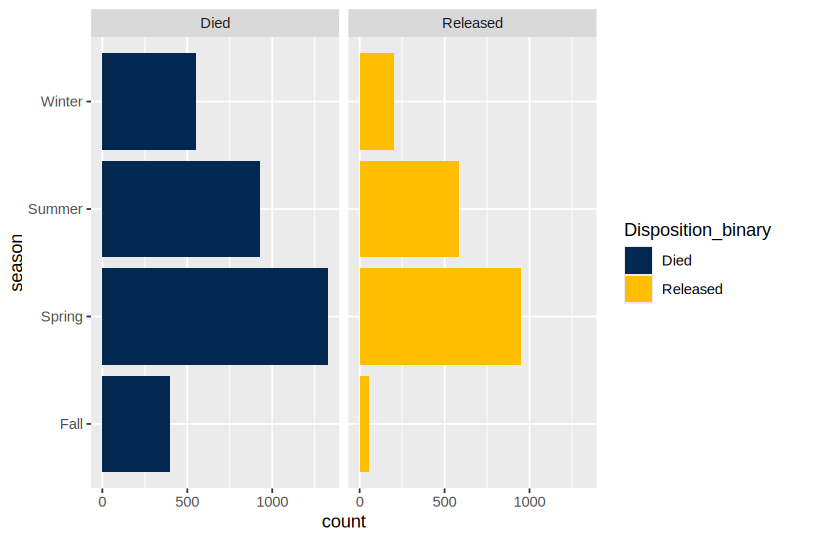

In [14]:
ggplot(df, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:** Looks like there might be an association between season and death, increassing on spring time.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2667,0.6449819
Lindsey,Released,1468,0.3550181
Santa Barbara,Died,41,0.5540541
Santa Barbara,Released,33,0.4459459
malibu,Died,498,0.6295828
malibu,Released,293,0.3704172


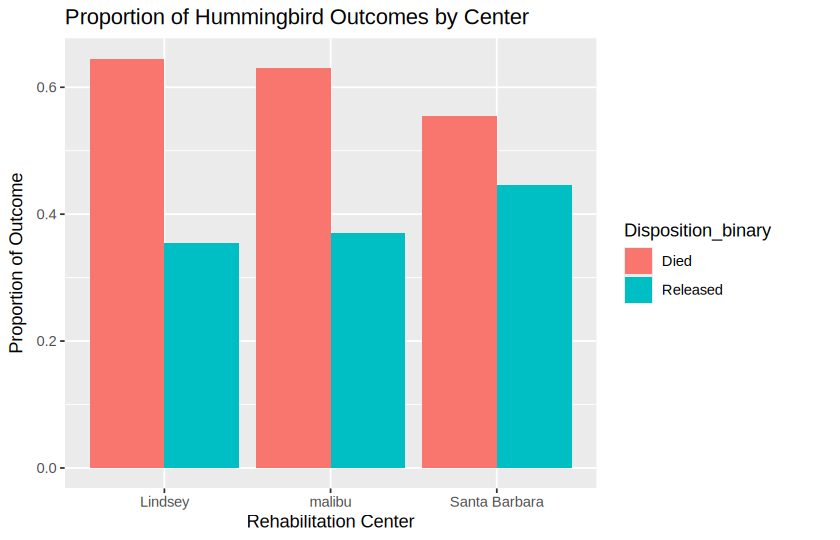

In [15]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation Center") +
  ylab("Proportion of Outcome") +
  labs(title = "Proportion of Hummingbird Outcomes by Center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4149                0
  Selasphorus                        0              851

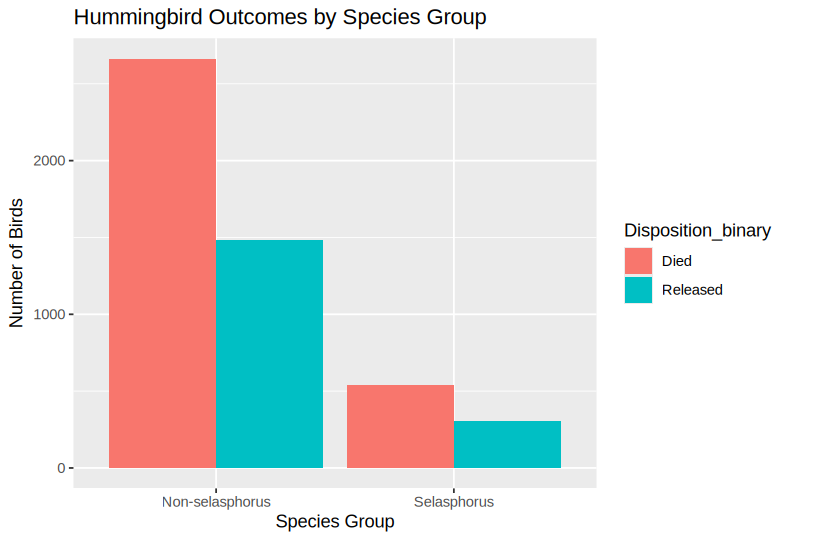

In [16]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

ggplot(species_distribution, aes(x = Species_group, y = count, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species Group") +
  ylab("Number of Birds") +
  labs(title = "Hummingbird Outcomes by Species Group")

✍️ **Your answer:**

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [17]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ **Your answer:** Format tells R how to read the data string, but if we swap the format, R understand the monht values 13 as wrong, causing to show a NA or warning.  

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `____` Why?

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [18]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

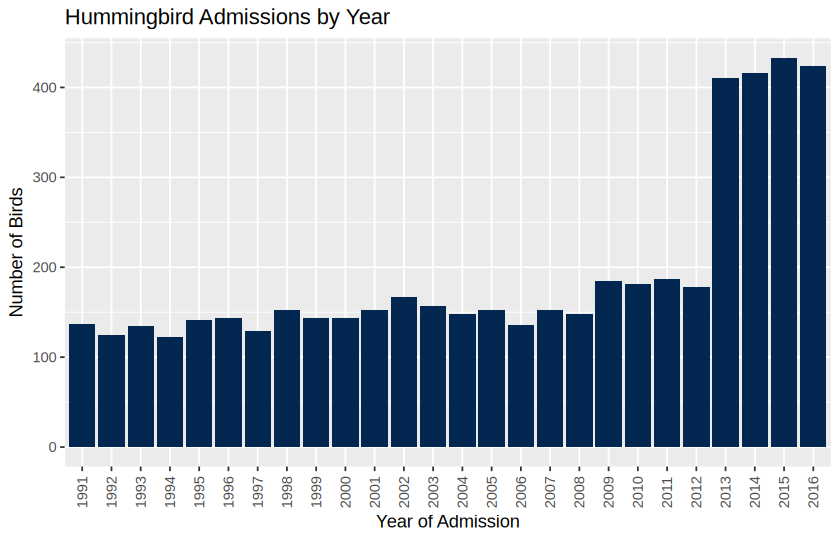

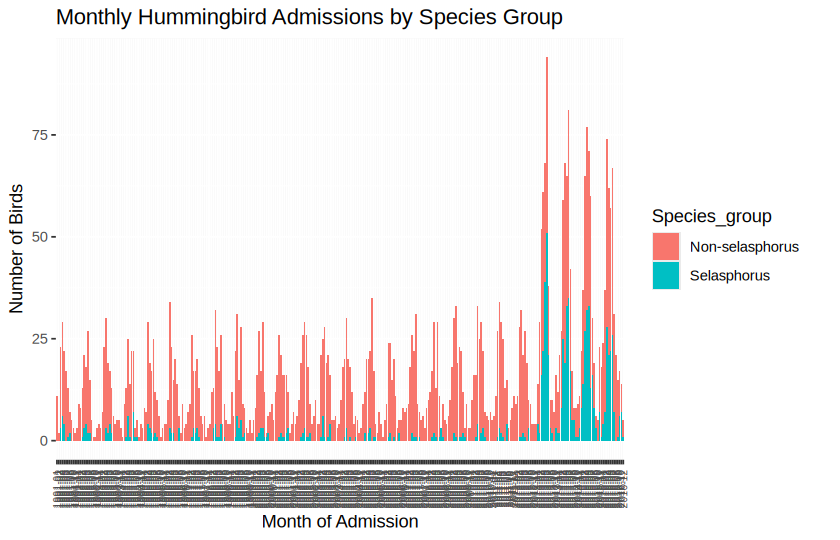

In [19]:
# First, make sure both admissions summary datasets are prepared
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

# Plot admissions by year
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year of Admission") +
  ylab("Number of Birds") +
  labs(title = "Hummingbird Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

# Prepare monthly admissions data by Species group from the model_data
monthly_species_admissions <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

# Plot the timeline showing admissions for the two distinct species groups over time
ggplot(monthly_species_admissions, aes(x = Admitted_month, y = count, fill = Species_group)) +
  geom_col(position = "stack") +
  xlab("Month of Admission") +
  ylab("Number of Birds") +
  labs(title = "Monthly Hummingbird Admissions by Species Group") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, size = 6))




**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [20]:
model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  count(Admitted_year, Place) %>%
  as.data.frame() %>%
  print()

   Admitted_year         Place   n
1           1991       Lindsey 137
2           1992       Lindsey 125
3           1993       Lindsey 135
4           1994       Lindsey 122
5           1995       Lindsey 141
6           1996       Lindsey 144
7           1997       Lindsey 129
8           1998       Lindsey 153
9           1999       Lindsey 143
10          2000       Lindsey 143
11          2001       Lindsey 152
12          2002       Lindsey 167
13          2003       Lindsey 157
14          2004       Lindsey 148
15          2005       Lindsey 153
16          2006       Lindsey 136
17          2007       Lindsey 152
18          2008       Lindsey 148
19          2009       Lindsey 185
20          2010       Lindsey 181
21          2011       Lindsey 187
22          2012       Lindsey 177
23          2012        malibu   1
24          2013       Lindsey 190
25          2013        malibu 221
26          2014       Lindsey 201
27          2014        malibu 215
28          2015    

✍️ **Your answer:** The sudden increase in admissions is not because hummingbirds got into more trouble, but because new rehabilitation centers joined the dataset. Prior to 2012, only the "Lindsey" center was reporting data. The "malibu" center joined with full reporting starting in 2013 (contributing over 200 cases per year), and the "Santa Barbara" center joined later in 2016.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [21]:
# your detective work here

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**  It was really nice to play with a large data set and been able to arrenge data to plot and have an idea on how the variables look when plotted.
There was a Typo in the fucntion Mutate that had the wrong pipe operator leading a warning. So, I had to investigate online and change %> to %>% so that the code executes correctly.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [22]:
beep_colab("smb_stage_clear")   # mission complete 🍄